# Predição de Preços de Ações com LSTM

Neste exemplo didático, vamos construir um modelo de Aprendizado Profundo utilizando redes recorrentes do tipo **LSTM (Long Short-Term Memory)** para tentar prever o preço futuro de fechamento de uma ação (utilizaremos a Apple, ticker `AAPL`). Os dados históricos reais serão obtidos via biblioteca `yfinance` diretamente do Yahoo Finance.

### Etapa 1: Instalação da Biblioteca

Primeiro, precisamos instalar o pacote `yfinance` para baixar os dados de mercado financeiro.

In [1]:
!pip install yfinance

### Etapa 2: Importação de Dependências

Importamos as bibliotecas necessárias para manipulação de dados, construção da rede neural com TensorFlow/Keras e visualização de gráficos.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

np.random.seed(42)
import tensorflow as tf
tf.random.set_seed(42)

### Etapa 3: Coleta dos Dados

Definimos o ticker do ativo desejado e determinamos o período histórico para download. Utilizaremos o preço de fechamento ajustado (`Adj Close`) para o treinamento.

/tmp/ipykernel_771/1002125660.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start='2018-01-01', end='2023-12-31')
[*********************100%***********************]  1 of 1 completed


,Close
Date,
2018-01-02,40.232384
2018-01-03,40.225372
2018-01-04,40.412220
2018-01-05,40.872330
2018-01-08,40.720516


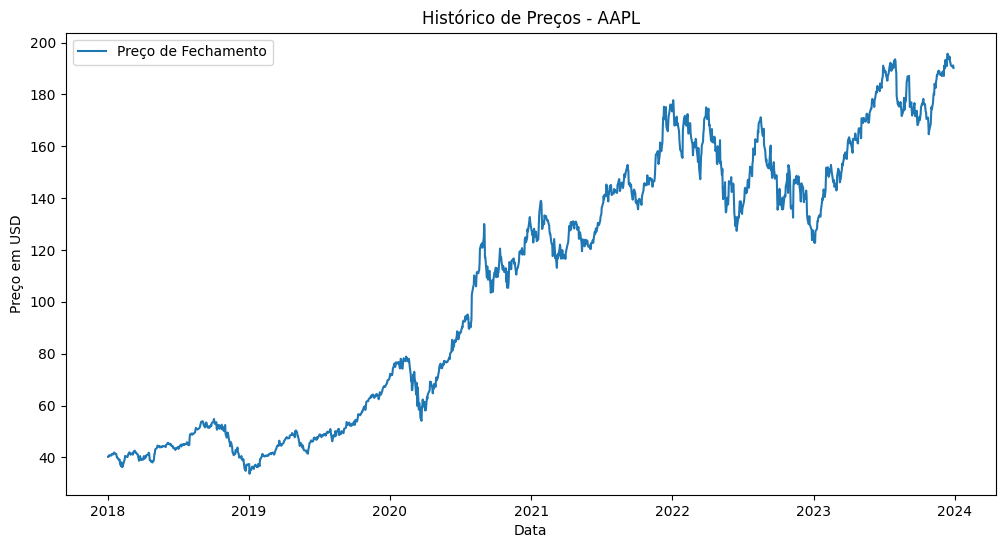

In [8]:
ticker = 'AAPL'
df = yf.download(ticker, start='2018-01-01', end='2023-12-31')

if 'Adj Close' in df.columns:
    data = df[['Adj Close']]
elif ('Adj Close', ticker) in df.columns:
    data = df[[('Adj Close', ticker)]]
else:
    data = df[['Close']]

data.columns = ['Close']
display(data.head())

plt.figure(figsize=(12, 6))
plt.plot(data, label='Preço de Fechamento')
plt.title('Histórico de Preços - AAPL')
plt.xlabel('Data')
plt.ylabel('Preço em USD')
plt.legend()
plt.show()

### Etapa 4: Pré-processamento e Divisão dos Dados

Normalizamos a escala dos dados para valores entre 0 e 1, que é o ideal para o bom desempenho de redes LSTM. Usamos 80% dos dados históricos para o treino e os 20% finais para o teste.

O modelo utilizará os dados das últimas 60 sessões para estimar e prever o preço do dia seguinte.

In [10]:
dataset = data.values
training_data_len = int(np.ceil(len(dataset) * 0.8))

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(dataset)

train_data = scaled_data[0:int(training_data_len), :]

X_train = []
y_train = []

for i in range(60, len(train_data)):
    X_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

X_train, y_train = np.array(X_train), np.array(y_train)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))

### Etapa 5: Construção e Treinamento da LSTM

Montamos uma arquitetura sequencial com duas camadas LSTM intercaladas com camadas de Dropout de 20% para regularização e prevenção de overfitting. O neurônio de saída linear fornecerá o preço predito diretamente.

In [11]:
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(units=1))

model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, batch_size=32, epochs=15, validation_split=0.1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - loss: 0.0332 - val_loss: 0.0102
Epoch 2/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0045 - val_loss: 0.0028
Epoch 3/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0032 - val_loss: 0.0023
Epoch 4/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0030 - val_loss: 0.0026
Epoch 5/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0029 - val_loss: 0.0021
Epoch 6/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0024 - val_loss: 0.0021
Epoch 7/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 8/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 9/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - loss: 0.0023 - val_loss: 0.0032
Epoch 10/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 11/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.0020 - val_loss: 0.0022
Epoch 12/15
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0

### Etapa 6: Preparação dos Dados de Teste e Predições

Criamos as sequências temporais contínuas de 60 dias para o conjunto de validação e aplicamos o modelo treinado para gerar as previsões. Logo em seguida, aplicamos a transformação inversa para trazer os preços simulados de volta à escala original em dólares.

In [12]:
test_data = scaled_data[training_data_len - 60:, :]
X_test = []
y_test = dataset[training_data_len:, :]

for i in range(60, len(test_data)):
    X_test.append(test_data[i-60:i, 0])

X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step


### Etapa 7: Visualização das Predições vs Valor Real

Por fim, montamos um gráfico que compara o histórico de treinamento, a evolução real do preço no conjunto de teste e as predições feitas pela nossa rede LSTM.

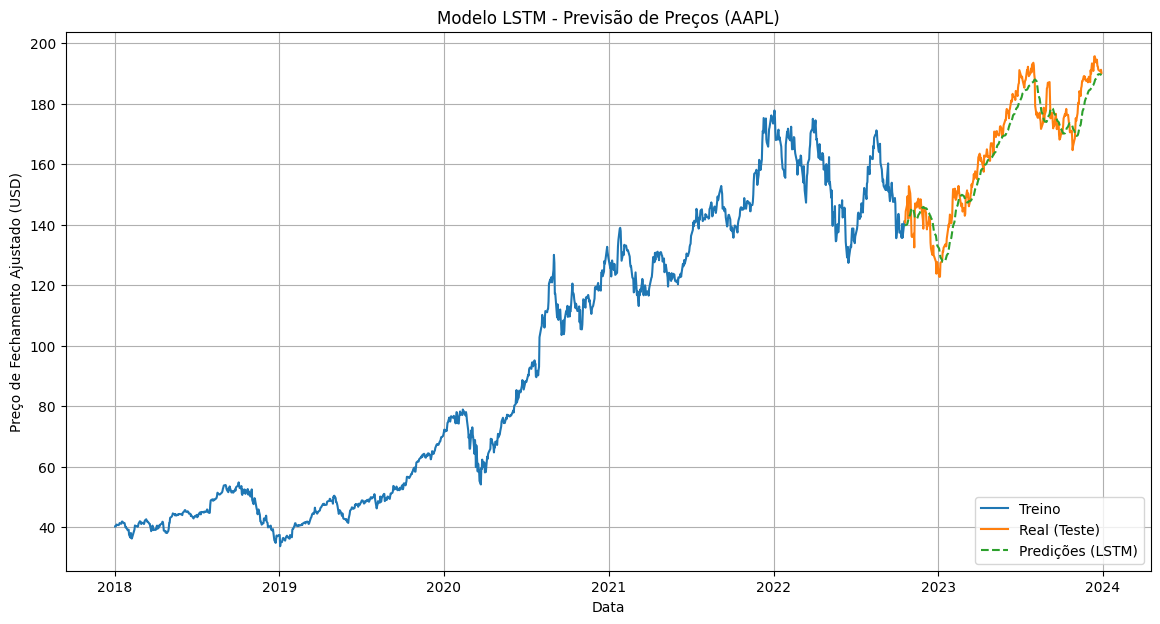

In [13]:
train = data[:training_data_len]
valid = data[training_data_len:].copy()
valid['Predictions'] = predictions

plt.figure(figsize=(14, 7))
plt.title('Modelo LSTM - Previsão de Preços (AAPL)')
plt.xlabel('Data')
plt.ylabel('Preço de Fechamento Ajustado (USD)')
plt.plot(train['Close'], label='Treino')
plt.plot(valid['Close'], label='Real (Teste)')
plt.plot(valid['Predictions'], label='Predições (LSTM)', linestyle='--')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()